# BotShield — Progress Check Demo
**CSCI 5772 · Eduardo Galvez (individual project)**

Run the cells top to bottom: **Normal system → Attack → Defense → Measured result**.

In [1]:
# Setup: works whether this notebook sits next to the botshield/ package or one folder above it
import os, sys, json
for root in [os.getcwd(), os.path.join(os.getcwd(), "botshield")]:
    if os.path.isdir(os.path.join(root, "botshield")) and os.path.isfile(os.path.join(root, "botshield", "sim.py")):
        PROJECT = root
        break
else:
    raise FileNotFoundError("Put this notebook in the project folder (the one containing README.md and botshield/).")
sys.path.insert(0, PROJECT)
EVID = os.path.join(PROJECT, "evidence")

from botshield.sim import run
from botshield.scenarios import SCENARIOS
from botshield.calibrate import calibrate
from IPython.display import Image, display

th_path = os.path.join(EVID, "thresholds.json")
TH = json.load(open(th_path)) if os.path.exists(th_path) else calibrate()

def show(rows):
    print(f"{'defense':24s}{'bots got':>10s}{'humans got':>12s}{'bots detected':>15s}{'benign flagged':>16s}{'us/request':>12s}")
    for label, r in rows:
        det = "n/a" if r["detection_rate"] != r["detection_rate"] else f"{100*r['detection_rate']:.0f}%"
        print(f"{label:24s}{r['bot_units']:>6d}/{r['inventory']}{r['human_units']:>12d}{det:>15s}"
              f"{100*r['false_positive_rate']:>15.1f}%{r['latency_us_mean']:>12.1f}")
print("Project:", PROJECT)
print("Calibrated thresholds (benign traffic only):", json.dumps(TH, indent=1))

Project: /home/claude/botshield
Calibrated thresholds (benign traffic only): {
 "device_only": {
  "throttle": 0.1317,
  "challenge": 0.15,
  "block": 0.2783
 },
 "behavior_only": {
  "throttle": 0.2231,
  "challenge": 0.2513,
  "block": 0.3434
 },
 "botshield": {
  "throttle": 0.2503,
  "challenge": 0.2836,
  "block": 0.466
 }
}


## 1. Problem and threat model
* **Protected assets:** limited inventory and fair access for real customers of a **mobile shopping app** during a product drop.
* **Attacker:** a scalper (OWASP OAT-005) with many accounts, Android emulators or racks of real phones, rotated/spoofed device IDs, proxies, human-like timing, and a CAPTCHA-solving service.
* **Out of scope:** payment fraud, server compromise, resale.

## 2. Architecture
Discrete-event testbed: the store drops 100 units at t = 60 s plus a 50-unit restock at t = 360 s, with a limit of 2 per account. 400 simulated app users include a realistic drop-time rush. There are 9 attack scenarios and 5 defenses.

**Risk score:** device score **D** (attestation, hardware/account fan-out, device age, sensor liveness, subnet density) and behavior score **B** (request rate, timing regularity, checkout speed, funnel skipping, missing touches), combined as

$$R = 1 - (1-D)(1-B)$$

Response steps: throttle → step-up challenge → block, with thresholds calibrated on legitimate traffic only.

In [2]:
for k, v in SCENARIOS.items():
    print(f"{k:24s} {v}")

benign_only              No attacker (false-positive reference)
single_bot               S1: one scripted bot, one account, direct checkout API
multi_acct_same_device   S2: 10 accounts on one emulator, datacenter IP
rotating_ids             S3: 30 accounts, rotated/spoofed device IDs, residential proxies, fake sensors
high_freq_monitor        S4: 5 accounts polling inventory every ~0.1 s
parallel_checkout        S5: 10 accounts firing 8 concurrent checkouts each
timing_mimicry           S6: 30 emulators with human-like timing, injected touches, fake sensors
phone_farm_rotation      S7: 10 real phones x 3 app reinstalls (device-ID rotation), scripted
phone_farm_scripted      S8: 30 real aged phones on a motion rig, one account each, scripted fast checkout
phone_farm_mimicry       S9: 30 real aged phones on a shelf, human-like timing (hardest case)


## 3. Normal run (no attacker)

In [3]:
show([("no defense", run("benign_only", "none", 1))])

defense                   bots got  humans got  bots detected  benign flagged  us/request
no defense                   0/150         150            n/a            0.0%         0.5


## 4. Attack: S6 — emulator farm with human-like timing
The rate-limit baseline does not stop it.

In [4]:
S = "timing_mimicry"
show([("no defense", run(S, "none", 1)),
      ("rate limit (baseline)", run(S, "rate_limit", 1))])

defense                   bots got  humans got  bots detected  benign flagged  us/request
no defense                  55/150          95             0%            0.0%         0.6
rate limit (baseline)       55/150          95             0%            0.0%         1.5


## 5. Defense

In [5]:
show([("device-only", run(S, "device_only", 1, TH["device_only"])),
      ("behavior-only", run(S, "behavior_only", 1, TH["behavior_only"])),
      ("BotShield (combined)", run(S, "botshield", 1, TH["botshield"]))])

defense                   bots got  humans got  bots detected  benign flagged  us/request
device-only                  0/150         150           100%            5.8%        58.9
behavior-only               55/150          95             0%            1.5%        54.4
BotShield (combined)         0/150         150           100%            2.5%        53.4


### Why: score breakdown (monitor mode, highest score per account)

In [6]:
m = run(S, "botshield", 1)["_scores"]
bots = sorted([(v[0], k, v) for k, v in m.items() if v[3]], reverse=True)
ben  = sorted([(v[0], k, v) for k, v in m.items() if not v[3]], reverse=True)
t = TH["botshield"]
print(f"thresholds: throttle R>={t['throttle']}, challenge R>={t['challenge']}, block R>={t['block']}")
s, k, v = bots[len(bots)//2]; print(f"median bot account     D={v[1]:.2f}  B={v[2]:.2f}  R={s:.2f}")
s, k, v = ben[len(ben)//50];  print(f"98th-pct real customer D={v[1]:.2f}  B={v[2]:.2f}  R={s:.2f}")

thresholds: throttle R>=0.2503, challenge R>=0.2836, block R>=0.466
median bot account     D=0.45  B=0.13  R=0.52
98th-pct real customer D=0.00  B=0.29  R=0.29


## 6. The opposite case: S8 — real, clean phones with scripted checkout
The device view sees nothing wrong; behavior gives the bots away.

In [7]:
S8 = "phone_farm_scripted"
show([("rate limit (baseline)", run(S8, "rate_limit", 1)),
      ("device-only", run(S8, "device_only", 1, TH["device_only"])),
      ("behavior-only", run(S8, "behavior_only", 1, TH["behavior_only"])),
      ("BotShield (combined)", run(S8, "botshield", 1, TH["botshield"]))])

defense                   bots got  humans got  bots detected  benign flagged  us/request
rate limit (baseline)       60/150          90             0%            0.0%         1.4
device-only                 60/150          90             0%            5.8%        53.9
behavior-only                0/150         150           100%            1.5%        54.2
BotShield (combined)         9/150         141           100%            2.5%        53.8


## 7. Results across all scenarios (5 seeds each, from `scripts/run_experiments.py`)

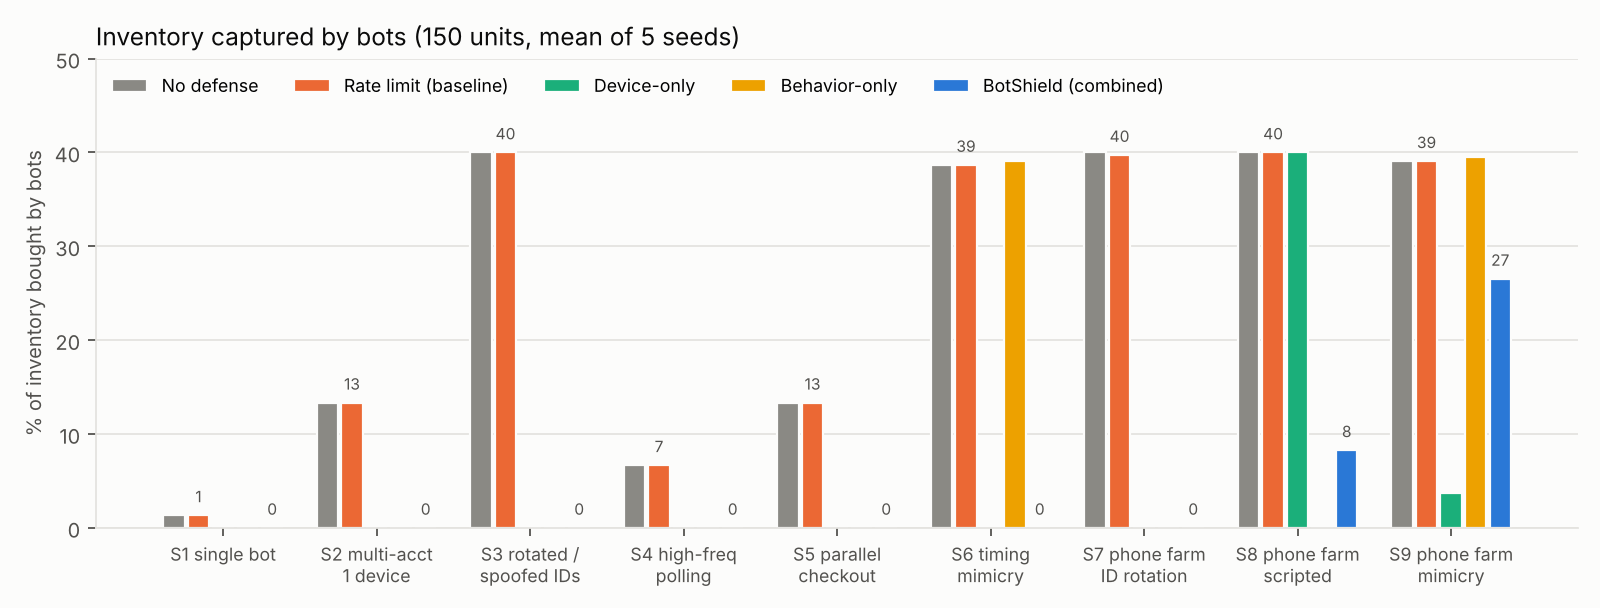

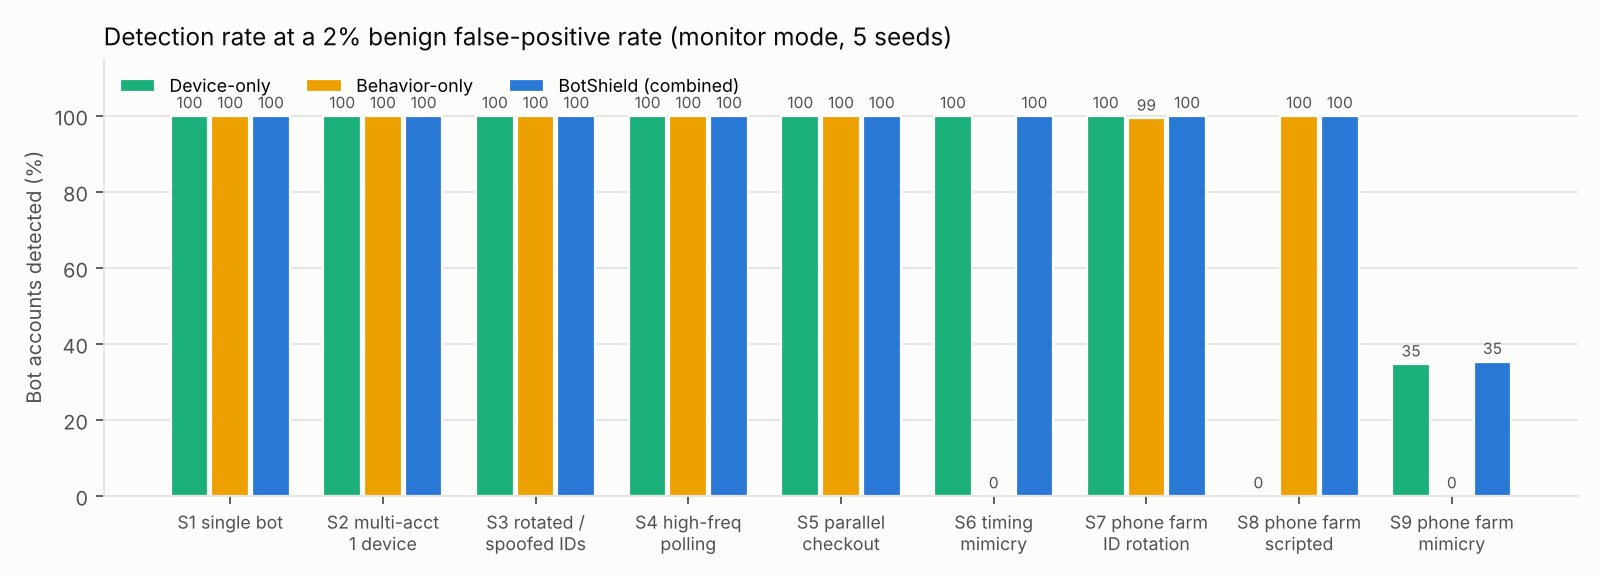

In [8]:
display(Image(os.path.join(EVID, "fig1_bot_inventory_share.png")))
display(Image(os.path.join(EVID, "fig2_ablation_detection.png")))

## 8. Honest failure and remaining work
S9: real, aged phones that also use human timing sit inside the cloud of real customers. At a 2% false-positive rate only about 35% are detected.

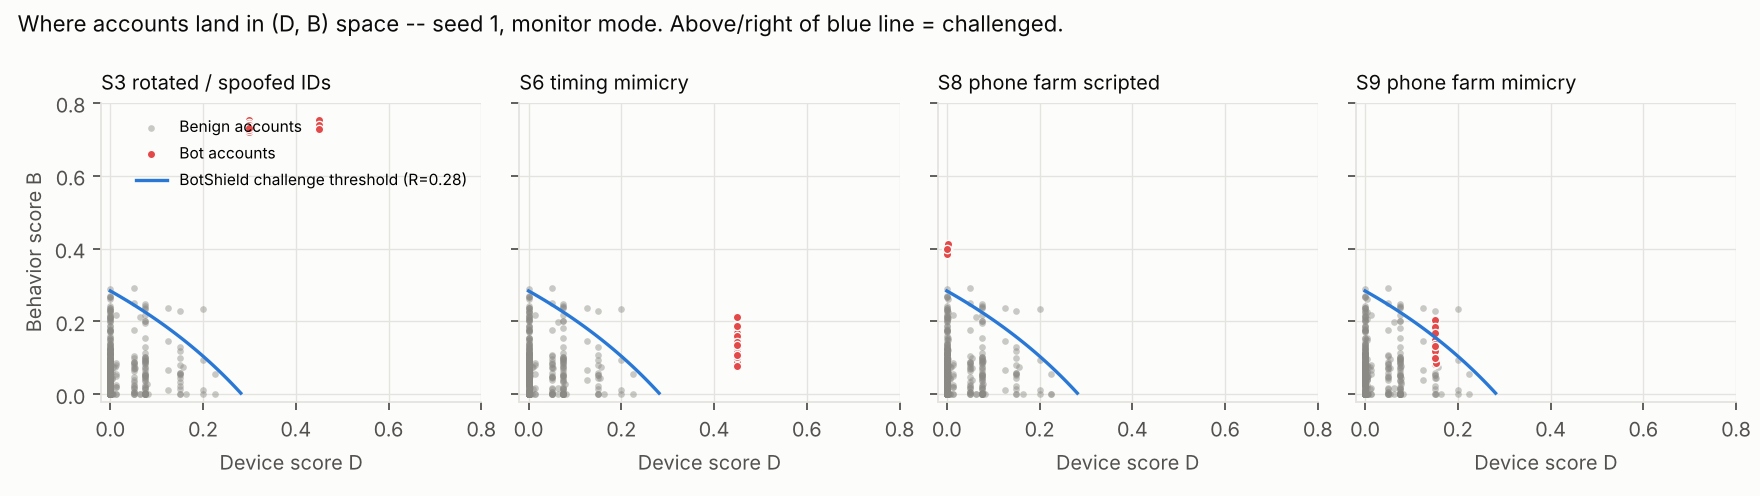

In [9]:
display(Image(os.path.join(EVID, "fig3_score_space.png")))

**Bugs found by testing (fixed):** a spoofed device ID could get the real owner flagged; our own throttle hid the bots' checkout speed.

**Next steps:**
1. Add sensor time-series features and cross-account synchronization features (for S9).
2. Learn the score weights instead of hand-setting them.
3. Sweep attacker budgets and inventory sizes.
4. Build an HTTP/Playwright version of the store to measure latency and compare against FingerprintJS BotD.

**Team:** individual project — architecture, simulation, attacks, detector, and evaluation by Eduardo Galvez.